In [3]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing


In [4]:
df = fetch_california_housing(as_frame=True).frame


In [8]:
df.count()

MedInc         20640
HouseAge       20640
AveRooms       20640
AveBedrms      20640
Population     20640
AveOccup       20640
Latitude       20640
Longitude      20640
MedHouseVal    20640
dtype: int64

In [13]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


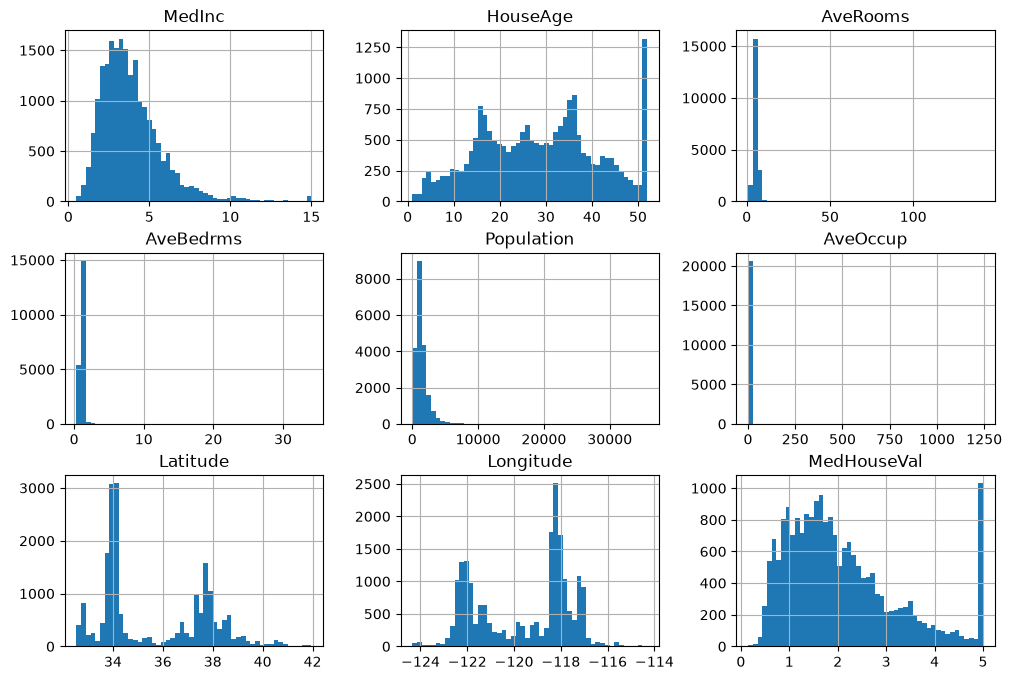

In [14]:
df.hist(bins=50, figsize=(12, 8)); plt.show()


In [15]:
n0 = len(df)
df = df[(df.MedHouseVal < 5) & (df.AveRooms < 20) & (df.AveOccup < 10) & (df.AveBedrms < 5)]
print("removed:", n0 - len(df))

removed: 1095


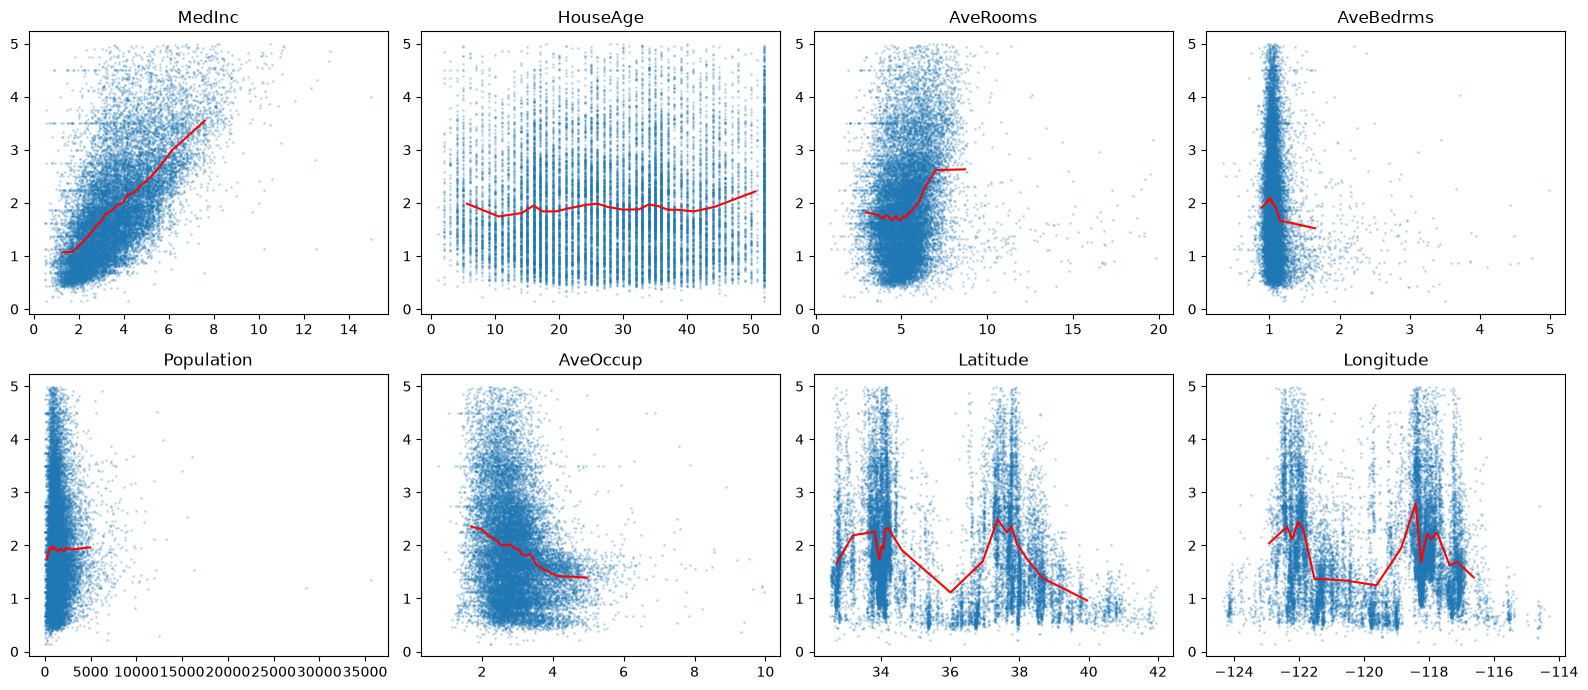

In [ ]:
feats = [c for c in df.columns if c != "MedHouseVal"]
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axs.ravel(), feats):
    ax.scatter(df[f], df.MedHouseVal, s=1, alpha=0.2)
    b = pd.qcut(df[f], 20, duplicates="drop")
    m = df.groupby(b, observed=True).agg(x=(f, "mean"), 
                                         y=("MedHouseVal", "mean"))
    ax.plot(m.x, m.y, "r"); ax.set_title(f)
plt.tight_layout(); plt.show()

In [1]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

In [2]:
lr = LinearRegression()
x= df[feats]
Y= df["MedHouseVal"]
Xtr, Xte, ytr, yte = train_test_split(x, Y, test_size=0.2, random_state=42)



NameError: name 'df' is not defined

In [23]:
lr.fit(Xtr, ytr)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.43, 0.01,-0.12,...,-0.28,-0.39,-0.38]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-31.55
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [ ]:
pred = lr.predict(Xte)
res = yte - pred #residuals


In [28]:
print("R2:", r2_score(yte, pred))
print("RMSE:", np.sqrt(mean_squared_error(yte, pred)))

R2: 0.6248385516143946
RMSE: 0.5989121732506353


[Text(0.5, 1.0, 'Residuals vs MedInc'),
 Text(0.5, 0, 'MedInc'),
 Text(0, 0.5, 'Residual')]

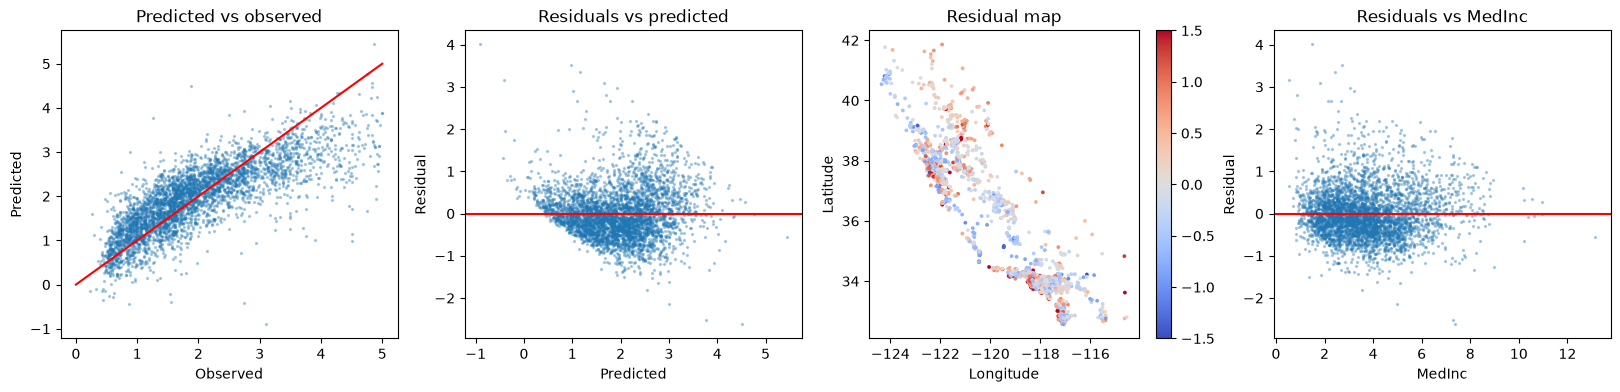

In [33]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].scatter(yte, pred, s=2, alpha=0.3)
ax[0].plot([0, 5], [0, 5], "r")
ax[0].set(title="Predicted vs observed", xlabel="Observed", ylabel="Predicted")

ax[1].scatter(pred, res, s=2, alpha=0.3)
ax[1].axhline(0, c="r")
ax[1].set(title="Residuals vs predicted", xlabel="Predicted", ylabel="Residual")

sc = ax[2].scatter(Xte.Longitude, Xte.Latitude, c=res, s=3, cmap="coolwarm", vmin=-1.5, vmax=1.5)
plt.colorbar(sc, ax=ax[2])
ax[2].set(title="Residual map", xlabel="Longitude", ylabel="Latitude")

ax[3].scatter(Xte.MedInc, res, s=2, alpha=0.3)
ax[3].axhline(0, c="r")
ax[3].set(title="Residuals vs MedInc", xlabel="MedInc", ylabel="Residual")

